[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Ahmed-Bayoumy/MECH559/blob/HEAD/L10/L10_nelder_mead.ipynb)

# The Nelder-Mead Simplex Algorithm
### MECH 559 - Systems Optimization - L10
### Course Instructor: Dr. Ahmed Bayoumy
Author of the notebook: Dr. Ahmed Bayoumy

Companion notebook to the Nelder-Mead (NM) slides in the *Heuristics* section of the
lecture. NM keeps a simplex of $n+1$ points and replaces its worst vertex using four
geometric transformations: **reflection**, **expansion**, **contraction** (outside or
inside) and **shrink**. We implement the algorithm exactly as on the slides, visualize each
transformation, run it on the Rosenbrock function (the "execution example" slide), and check
our implementation against SciPy's.

## Learning objectives

By the end, students should be able to:

1. Compute the reflection $x^r$, expansion $x^e$, outside/inside contraction $x^{oc}$,
   $x^{ic}$ and shrink points from the centroid $x^c$ of the best $n$ vertices.
2. Implement the NM decision rules and count the evaluations each iteration costs
   (1 for a reflection, 2 for an expansion or contraction, $n+2$ for a shrink).
3. Trace a full NM run, relate the operation sequence to the shape of the simplex, and
   choose stopping criteria (simplex diameter, budget).
4. Use `scipy.optimize.minimize(method="Nelder-Mead")` and interpret its options.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize

try:
    import ipywidgets as widgets
    from IPython.display import display
    WIDGETS_AVAILABLE = True
except ImportError:
    WIDGETS_AVAILABLE = False

plt.rcParams.update({"font.size": 11, "figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25})
COLORS = {"simplex": "#D1495B", "fill": "#EDAE49", "r": "#1D5FA8", "e": "#2A9D5C", "oc": "#7B2CBF",
          "ic": "#00798C", "s": "#264653", "optimum": "#EDAE49"}
OPS = ["reflection", "expansion", "outside contraction", "inside contraction", "shrink"]
print(f"Optional widgets available: {WIDGETS_AVAILABLE}")

Optional widgets available: True


---
## 1. The transformations
#
Order the vertices so that $f(x^0) \le f(x^1) \le \dots \le f(x^n)$ and let
$x^c = \frac1n\sum_{i=0}^{n-1} x^i$ be the centroid of all vertices except the worst
$x^n$. With the standard coefficients:
#
$$
x^r = x^c + (x^c - x^n), \quad
x^e = x^c + 2(x^c - x^n), \quad
x^{oc} = x^c + \tfrac12(x^r - x^c), \quad
x^{ic} = x^c + \tfrac12(x^n - x^c),
$$
#
and a shrink replaces every $x^i$, $i \ge 1$, by $x^0 + \tfrac12(x^i - x^0)$.

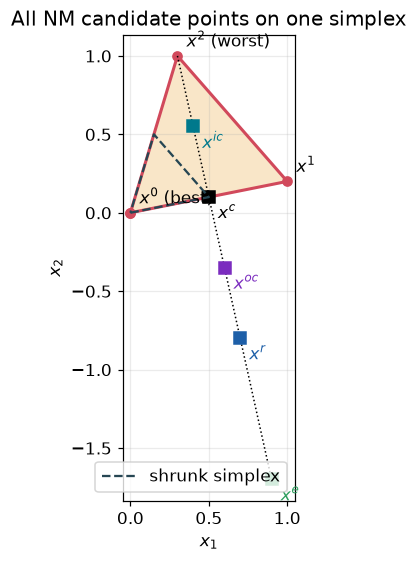

In [2]:
def nm_points(S):
    """Candidate points of one NM iteration for a simplex S already sorted best -> worst."""
    c = S[:-1].mean(axis=0)
    worst = S[-1]
    xr = c + (c - worst)
    return {"centroid": c, "r": xr, "e": c + 2 * (c - worst),
            "oc": c + 0.5 * (xr - c), "ic": c + 0.5 * (worst - c),
            "shrink": S[0] + 0.5 * (S[1:] - S[0])}


S_demo = np.array([[0.0, 0.0], [1.0, 0.2], [0.3, 1.0]])   # best, middle, worst
pts = nm_points(S_demo)

fig, ax = plt.subplots(figsize=(6.5, 5.5))
P = np.vstack([S_demo, S_demo[0]])
ax.fill(P[:, 0], P[:, 1], color=COLORS["fill"], alpha=0.3)
ax.plot(P[:, 0], P[:, 1], "o-", color=COLORS["simplex"], lw=2)
for lab, pt in zip(["$x^0$ (best)", "$x^1$", "$x^2$ (worst)"], S_demo):
    ax.annotate(lab, pt, textcoords="offset points", xytext=(6, 6))
ax.plot([S_demo[-1][0], pts["e"][0]], [S_demo[-1][1], pts["e"][1]], ":", color="k", lw=1)
for key, lab in [("centroid", "$x^c$"), ("r", "$x^r$"), ("e", "$x^e$"), ("oc", "$x^{oc}$"), ("ic", "$x^{ic}$")]:
    color = COLORS.get(key, "k")
    ax.plot(*pts[key], "s", color=color, ms=8)
    ax.annotate(lab, pts[key], textcoords="offset points", xytext=(6, -14), color=color)
shr = np.vstack([S_demo[0], pts["shrink"], S_demo[0]])
ax.plot(shr[:, 0], shr[:, 1], "--", color=COLORS["s"], lw=1.5, label="shrunk simplex")
ax.set(xlabel="$x_1$", ylabel="$x_2$", aspect="equal", title="All NM candidate points on one simplex")
ax.legend(loc="lower right")
plt.show()

All candidates lie on the line from the worst vertex through the centroid: NM is
essentially a **line search along $x^c - x^n$**, plus a shrink when that line fails.
#
---
## 2. The algorithm
#
One iteration, as in the slides (Lagarias et al. tie-breaking aside):
#
1. **Reflect.** If $f(x^0) \le f(x^r) < f(x^{n-1})$, accept $x^r$.
2. **Expand.** If $f(x^r) < f(x^0)$, accept the better of $x^e$ and $x^r$.
3. **Contract.** If $f(x^{n-1}) \le f(x^r) < f(x^n)$, try $x^{oc}$ (accept if $f(x^{oc}) \le f(x^r)$);
   if $f(x^r) \ge f(x^n)$, try $x^{ic}$ (accept if $f(x^{ic}) < f(x^n)$).
4. **Shrink** if the contraction failed.
#
Our implementation records every simplex, the operation performed and the number of
function evaluations used.

In [3]:
def nelder_mead(func, simplex, max_iter=500, tol_diam=1e-8, max_eval=np.inf):
    S = np.array(simplex, dtype=float)
    fv = np.array([func(v) for v in S])
    n_eval = len(S)
    history = [{"S": S.copy(), "f": fv.copy(), "op": "initial", "n_eval": n_eval}]
    for _ in range(max_iter):
        order = np.argsort(fv, kind="stable")
        S, fv = S[order], fv[order]
        if max(np.linalg.norm(a - b) for a in S for b in S) < tol_diam or n_eval >= max_eval:
            break
        p = nm_points(S)
        fr = func(p["r"]); n_eval += 1
        if fv[0] <= fr < fv[-2]:
            S[-1], fv[-1], op = p["r"], fr, "reflection"
        elif fr < fv[0]:
            fe = func(p["e"]); n_eval += 1
            if fe < fr:
                S[-1], fv[-1], op = p["e"], fe, "expansion"
            else:
                S[-1], fv[-1], op = p["r"], fr, "reflection"
        else:
            outside = fr < fv[-1]
            xc = p["oc"] if outside else p["ic"]
            fc = func(xc); n_eval += 1
            if (outside and fc <= fr) or (not outside and fc < fv[-1]):
                S[-1], fv[-1] = xc, fc
                op = "outside contraction" if outside else "inside contraction"
            else:
                S[1:] = p["shrink"]
                fv[1:] = [func(v) for v in S[1:]]
                n_eval += len(S) - 1
                op = "shrink"
        history.append({"S": S.copy(), "f": fv.copy(), "op": op, "n_eval": n_eval})
    order = np.argsort(fv, kind="stable")
    return S[order][0], fv[order][0], history


def rosenbrock(x):
    return (1 - x[0]) ** 2 + 100 * (x[1] - x[0] ** 2) ** 2


x_start = np.array([-1.2, 1.0])
S0 = np.array([x_start, x_start + [0.5, 0.0], x_start + [0.0, 0.5]])
x_nm, f_nm, hist = nelder_mead(rosenbrock, S0)
counts = {op: sum(h["op"] == op for h in hist) for op in OPS}
print(f"NM from {x_start}: x = {np.round(x_nm, 6)}, f = {f_nm:.2e}")
print(f"iterations: {len(hist) - 1}, evaluations: {hist[-1]['n_eval']}")
print("operations:", counts)

NM from [-1.2  1. ]: x = [1. 1.], f = 1.74e-17
iterations: 110, evaluations: 210
operations: {'reflection': 26, 'expansion': 14, 'outside contraction': 10, 'inside contraction': 60, 'shrink': 0}


# > **Predict:** Rosenbrock's valley is long, narrow and curved. Which operations should
# > dominate while NM travels along the valley, and which near the minimizer $(1,1)$?

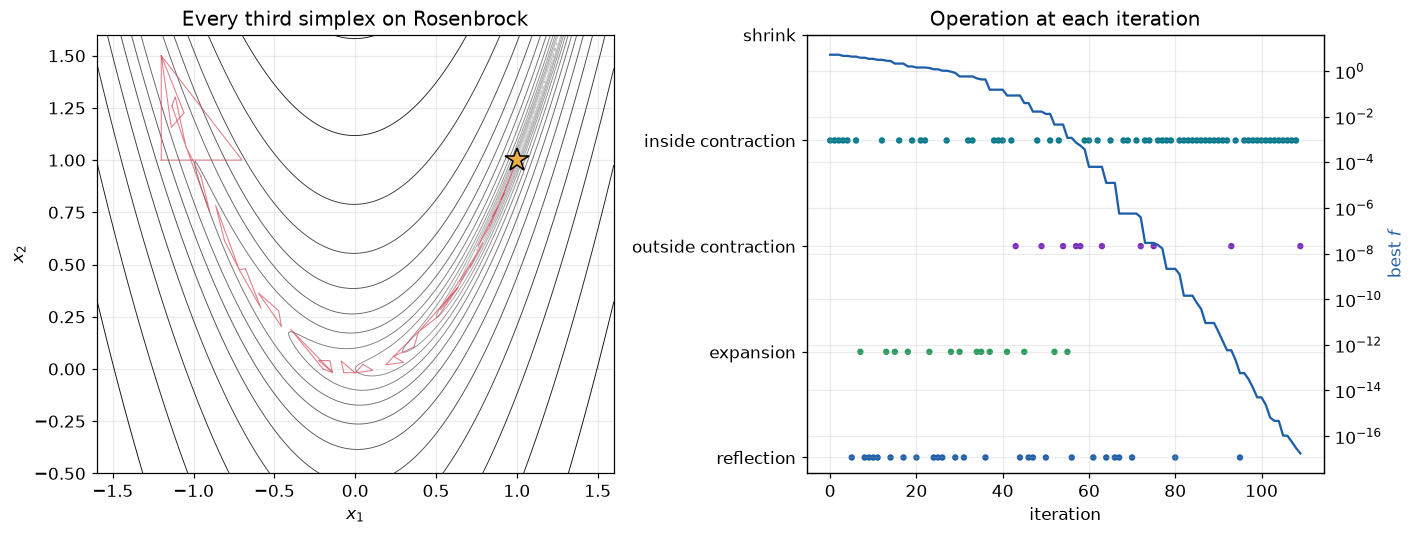

In [4]:
xs = np.linspace(-1.6, 1.6, 300)
ys = np.linspace(-0.5, 1.6, 300)
X, Y = np.meshgrid(xs, ys)
Z = (1 - X) ** 2 + 100 * (Y - X ** 2) ** 2

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].contour(X, Y, np.log10(Z + 1e-12), levels=25, cmap="Greys", linewidths=0.6)
for h in hist[::3]:
    P = np.vstack([h["S"], h["S"][0]])
    axes[0].plot(P[:, 0], P[:, 1], "-", color=COLORS["simplex"], lw=0.7, alpha=0.7)
axes[0].plot(1, 1, "*", color=COLORS["optimum"], ms=16, mec="k")
axes[0].set(xlabel="$x_1$", ylabel="$x_2$", title="Every third simplex on Rosenbrock")

ks = np.arange(len(hist) - 1)
op_index = [OPS.index(h["op"]) for h in hist[1:]]
op_colors = [COLORS[key] for key in ("r", "e", "oc", "ic", "s")]
axes[1].scatter(ks, op_index, c=[op_colors[i] for i in op_index], s=10)
axes[1].set(yticks=range(len(OPS)), yticklabels=OPS, xlabel="iteration", title="Operation at each iteration")
ax2 = axes[1].twinx()
ax2.semilogy(ks, [h["f"].min() for h in hist[1:]], color=COLORS["r"], lw=1.5)
ax2.set_ylabel("best $f$", color=COLORS["r"])
plt.tight_layout()
plt.show()

Along the valley NM mixes **reflections and expansions** (the simplex tumbles and
stretches along the valley floor) with contractions that re-orient it in the bends; near
the minimizer, **contractions** dominate and the simplex closes in on $(1, 1)$.
#
---
## 3. Cost per iteration and stopping
#
The slides count the evaluations per iteration: 1 (reflection), 2 (expansion or
contraction) or $n + 2$ (shrink, including the failed contraction). We verify this from
the history and look at the simplex diameter, the usual stopping criterion.

reflection          :  26 iterations, evaluations each = [1, 2]
expansion           :  14 iterations, evaluations each = [2]
outside contraction :  10 iterations, evaluations each = [2]
inside contraction  :  60 iterations, evaluations each = [2]


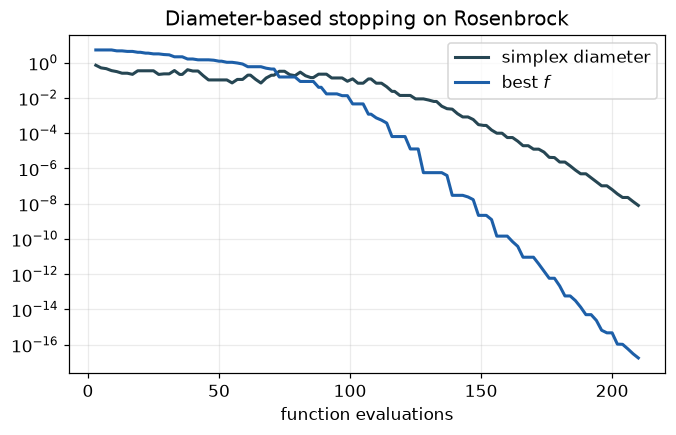

In [5]:
cost = {op: [] for op in OPS}
for prev, cur in zip(hist, hist[1:]):
    cost[cur["op"]].append(cur["n_eval"] - prev["n_eval"])
for op in OPS:
    if cost[op]:
        print(f"{op:20s}: {len(cost[op]):3d} iterations, evaluations each = {sorted(set(cost[op]))}")

diam = [max(np.linalg.norm(a - b) for a in h["S"] for b in h["S"]) for h in hist]
fig, ax = plt.subplots(figsize=(7, 4))
ax.semilogy([h["n_eval"] for h in hist], diam, color=COLORS["s"], lw=2, label="simplex diameter")
ax.semilogy([h["n_eval"] for h in hist], [h["f"].min() for h in hist], color=COLORS["r"], lw=2, label="best $f$")
ax.set(xlabel="function evaluations", title="Diameter-based stopping on Rosenbrock")
ax.legend()
plt.show()

A reflection costs 2 evaluations when it is accepted *after* a rejected expansion
($f(x^e) \ge f(x^r)$). No shrink occurred in this run - on smooth functions shrinks are
rare; they appear when a contraction fails, e.g. near kinks or with noisy values.
#
---
## 4. Comparison with SciPy
#
SciPy implements the same algorithm (with adaptive coefficients available through
`adaptive=True`). We pass our initial simplex so both runs start identically.

In [6]:
res = minimize(rosenbrock, x_start, method="Nelder-Mead",
               options={"initial_simplex": S0, "xatol": 1e-8, "fatol": 1e-12, "maxfev": 5000})
print(f"SciPy : x = {np.round(res.x, 6)}, f = {res.fun:.2e}, evaluations = {res.nfev}, iterations = {res.nit}")
print(f"ours  : x = {np.round(x_nm, 6)}, f = {f_nm:.2e}, evaluations = {hist[-1]['n_eval']}, iterations = {len(hist) - 1}")

SciPy : x = [1. 1.], f = 1.74e-17, evaluations = 210, iterations = 111
ours  : x = [1. 1.], f = 1.74e-17, evaluations = 210, iterations = 110


Both runs visit exactly the same points and use the same number of evaluations: our
implementation and SciPy's follow the same rules. (They can differ in general through the
stopping tests - SciPy stops when *both* the vertex spread and the function-value spread are
below `xatol` and `fatol` - and through tie-breaking details.)
#
---
## 5. Step through a run
#
Use the slider to replay the run iteration by iteration (the static fallback shows a few
snapshots).

In [7]:
def plot_iteration(k=0):
    h = hist[k]
    fig, ax = plt.subplots(figsize=(6.5, 5))
    ax.contour(X, Y, np.log10(Z + 1e-12), levels=25, cmap="Greys", linewidths=0.6)
    for j in range(max(0, k - 5), k):
        P = np.vstack([hist[j]["S"], hist[j]["S"][0]])
        ax.plot(P[:, 0], P[:, 1], "-", color="0.6", lw=0.8)
    P = np.vstack([h["S"], h["S"][0]])
    ax.fill(P[:, 0], P[:, 1], color=COLORS["fill"], alpha=0.4)
    ax.plot(P[:, 0], P[:, 1], "o-", color=COLORS["simplex"], lw=1.5)
    ax.plot(1, 1, "*", color=COLORS["optimum"], ms=16, mec="k")
    ax.set(xlabel="$x_1$", ylabel="$x_2$",
           title=f"iteration {k}: {h['op']}  (best f = {h['f'].min():.2e}, {h['n_eval']} evals)")
    plt.show()


if WIDGETS_AVAILABLE:
    display(widgets.interactive(plot_iteration, k=widgets.IntSlider(
        value=0, min=0, max=len(hist) - 1, step=1, description="iteration")))
else:
    for k in (0, 20, 60):
        plot_iteration(k)

interactive(children=(IntSlider(value=0, description='iteration', max=110), Output()), _dom_classes=('widget-iâ€¦

---
## Takeaways
#
1. Every NM candidate lies on the line from the worst vertex through the centroid of the
   others; a shrink is the fallback when that line search fails.
2. An iteration costs 1, 2 or $n+2$ evaluations; on Rosenbrock, reflections and expansions
   move the simplex along the valley, contractions refine it near the minimizer.
3. NM stops on simplex size (and/or function-value spread) or budget; it never uses
   gradients, which is why it is so popular with engineers.
4. NM is a **heuristic**: it works very well here, but it has no general convergence
   guarantee - the next notebook shows how it can fail.